# Symbolic Detective v0.2 — Geometry Ablation Analysis

**Comparison:** `v0.2_dev_baseline` vs. `exp01_harmonics`:
1. **Retrieval CV:** Hit@1, Hit@5 and MRR, overall and for `eight_pointed_star`, at every α.
2. **Paired fold changes:** Whether an improvement is consistent across the same five folds.
3. **Top-1 multi-class discrimination:** Per-class precision/recall/F1, plus micro/macro/weighted averages.

**Reading the results:** CV means/SDs are computed across folds; discrimination reports are based on **pooled predictions** across folds. Those summaries are not interchangeable. Positive Δ means harmonics > baseline.

*Class voting is a separate evaluation; these files contain retrieval and Top-1 discrimination only.*

## 1. Load baseline and harmonics JSON

In [41]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 120)

cwd = Path.cwd()
search_roots = [cwd, cwd.parent]

def first_existing(paths):
    for path in paths:
        if path.is_file():
            return path
    raise FileNotFoundError("None of these paths exist:\n" + "\n".join(map(str, paths)))

baseline_path = first_existing(
    [root / "results/v0.2_dev_baseline/retrieval_metrics.json" for root in search_roots]
    + [cwd / "retrieval_metrics.json"]
)
harmonics_path = first_existing(
    [root / "results/v0.2_dev/exp01_harmonics/retrieval_metrics.json" for root in search_roots]
    + [cwd / "retrieval_metrics_harmonic.json"]
)

with baseline_path.open(encoding="utf-8") as f:
    baseline = json.load(f)
with harmonics_path.open(encoding="utf-8") as f:
    harmonics = json.load(f)

experiments = {"baseline": baseline, "harmonics": harmonics}
print("Baseline:", baseline_path, "[", baseline["experiment"], "]")
print("Harmonics:", harmonics_path, "[", harmonics["experiment"], "]")

Baseline: C:\Users\Maja\projects\symbolic-detective\results\v0.2_dev_baseline\retrieval_metrics.json [ v0.2_dev_baseline ]
Harmonics: C:\Users\Maja\projects\symbolic-detective\results\v0.2_dev\exp01_harmonics\retrieval_metrics.json [ exp01_harmonics ]


## 2. Cross-validation retrieval comparison

Compare the two representations for **every α** and for both evaluation scopes. The reported Δ is the difference between **unrounded** fold means.

In [42]:
def flatten_retrieval(data, experiment):
    rows = []
    for scope, configurations in data["cross_validation"].items():
        for cfg in configurations:
            for metric in ("hit_at_1", "hit_at_5", "mrr"):
                values = cfg[metric]
                rows.append({
                    "experiment": experiment,
                    "scope": scope,
                    "alpha": float(cfg["alpha"]),
                    "metric": metric,
                    "mean": values["mean"],
                    "std": values["std"],
                    "folds": values["folds"],
                })
    return pd.DataFrame(rows)

retrieval = pd.concat(
    [flatten_retrieval(data, name) for name, data in experiments.items()],
    ignore_index=True,
)

keys = ["scope", "alpha", "metric"]
a = retrieval.loc[retrieval.experiment == "baseline", keys + ["mean", "std", "folds"]].rename(
    columns={"mean": "baseline_mean", "std": "baseline_std", "folds": "baseline_folds"}
)
b = retrieval.loc[retrieval.experiment == "harmonics", keys + ["mean", "std", "folds"]].rename(
    columns={"mean": "harmonics_mean", "std": "harmonics_std", "folds": "harmonics_folds"}
)
comparison = a.merge(b, on=keys, validate="one_to_one")
comparison["delta"] = comparison["harmonics_mean"] - comparison["baseline_mean"]

columns = keys + ["baseline_mean", "baseline_std", "harmonics_mean", "harmonics_std", "delta"]
for scope in ("overall", "target_eight_pointed_star"):
    print("\n", scope.upper())
    display(comparison.loc[comparison.scope == scope, columns].round(4))


 OVERALL


,scope,alpha,metric,baseline_mean,baseline_std,harmonics_mean,harmonics_std,delta
0,overall,0.00,hit_at_1,0.6042,0.0636,0.6042,0.0636,0.0000
1,overall,0.00,hit_at_5,0.8769,0.0193,0.8769,0.0193,0.0000
2,overall,0.00,mrr,0.7200,0.0397,0.7200,0.0397,0.0000
3,overall,0.25,hit_at_1,0.6058,0.0374,0.5962,0.0645,-0.0095
4,overall,0.25,hit_at_5,0.8716,0.0428,0.8716,0.0527,0.0000
5,overall,0.25,mrr,0.7193,0.0359,0.7171,0.0528,-0.0022
6,overall,0.50,hit_at_1,0.4979,0.0749,0.5117,0.0553,0.0138
7,overall,0.50,hit_at_5,0.8907,0.0391,0.8940,0.0463,0.0033
8,overall,0.50,mrr,0.6654,0.0552,0.6703,0.0470,0.0049
9,overall,0.75,hit_at_1,0.3543,0.1102,0.3586,0.0729,0.0043



 TARGET_EIGHT_POINTED_STAR


,scope,alpha,metric,baseline_mean,baseline_std,harmonics_mean,harmonics_std,delta
15,target_eight_pointed_star,0.00,hit_at_1,0.7525,0.0589,0.7525,0.0589,0.0000
16,target_eight_pointed_star,0.00,hit_at_5,0.9600,0.0490,0.9600,0.0490,0.0000
17,target_eight_pointed_star,0.00,mrr,0.8293,0.0440,0.8293,0.0440,0.0000
18,target_eight_pointed_star,0.25,hit_at_1,0.7459,0.0863,0.7277,0.0784,-0.0182
19,target_eight_pointed_star,0.25,hit_at_5,0.9378,0.0510,0.9378,0.0510,0.0000
20,target_eight_pointed_star,0.25,mrr,0.8342,0.0750,0.8254,0.0678,-0.0088
21,target_eight_pointed_star,0.50,hit_at_1,0.6666,0.0755,0.6870,0.0857,0.0204
22,target_eight_pointed_star,0.50,hit_at_5,0.9600,0.0800,0.9800,0.0400,0.0200
23,target_eight_pointed_star,0.50,mrr,0.7866,0.0557,0.8007,0.0709,0.0140
24,target_eight_pointed_star,0.75,hit_at_1,0.4583,0.1183,0.4387,0.1211,-0.0196


### 2.1 Fold-by-fold paired differences

Because the JSON includes arrays of values for each fold, we can examine the **difference on each fold**, not just the difference between overall means. This assumes matching fold order / split; verify that the two evaluations used the same fold assignments.

In [43]:
fold_rows = []
for row in comparison.itertuples(index=False):
    original = np.asarray(row.baseline_folds, dtype=float)
    improved = np.asarray(row.harmonics_folds, dtype=float)
    if len(original) != len(improved):
        raise ValueError(f"Different fold counts: {row.scope}, α={row.alpha}, {row.metric}")
    for fold_i, (old, new) in enumerate(zip(original, improved), start=1):
        fold_rows.append({
            "scope": row.scope,
            "alpha": row.alpha,
            "metric": row.metric,
            "fold": fold_i,
            "baseline": old,
            "harmonics": new,
            "delta": new - old,
        })
fold_comparison = pd.DataFrame(fold_rows)

fold_summary = (
    fold_comparison.assign(
        improved=lambda x: x.delta > 1e-12,
        worsened=lambda x: x.delta < -1e-12,
        unchanged=lambda x: x.delta.abs() <= 1e-12,
    )
    .groupby(["scope", "alpha", "metric"], as_index=False)
    .agg(improved_folds=("improved", "sum"),
         worsened_folds=("worsened", "sum"),
         unchanged_folds=("unchanged", "sum"),
         mean_fold_delta=("delta", "mean"))
)

# Focus on Hybrid α=0.25 and geometric-only α=1.0, overall Hit@1.
display(fold_comparison.query(
    "scope == 'overall' and metric == 'hit_at_1' and alpha in [0.25, 1.0]"
).round(4))
display(fold_summary.query(
    "scope == 'overall' and metric == 'hit_at_1'"
).round(4))

,scope,alpha,metric,fold,baseline,harmonics,delta
15,overall,0.25,hit_at_1,1,0.6667,0.6863,0.0196
16,overall,0.25,hit_at_1,2,0.6200,0.6200,0.0000
17,overall,0.25,hit_at_1,3,0.6087,0.6304,0.0217
18,overall,0.25,hit_at_1,4,0.5652,0.5217,-0.0435
19,overall,0.25,hit_at_1,5,0.5682,0.5227,-0.0455
60,overall,1.00,hit_at_1,1,0.3529,0.3137,-0.0392
61,overall,1.00,hit_at_1,2,0.1800,0.1600,-0.0200
62,overall,1.00,hit_at_1,3,0.2174,0.1957,-0.0217
63,overall,1.00,hit_at_1,4,0.1739,0.1739,0.0000
64,overall,1.00,hit_at_1,5,0.4091,0.3409,-0.0682


,scope,alpha,metric,improved_folds,worsened_folds,unchanged_folds,mean_fold_delta
0,overall,0.00,hit_at_1,0,0,5,0.0000
3,overall,0.25,hit_at_1,2,2,1,-0.0095
6,overall,0.50,hit_at_1,2,3,0,0.0138
9,overall,0.75,hit_at_1,1,2,2,0.0043
12,overall,1.00,hit_at_1,0,4,1,-0.0298


### 2.2 Retrieval Δ by α (plots)

A negative bar means worse than baseline; a positive bar means better.

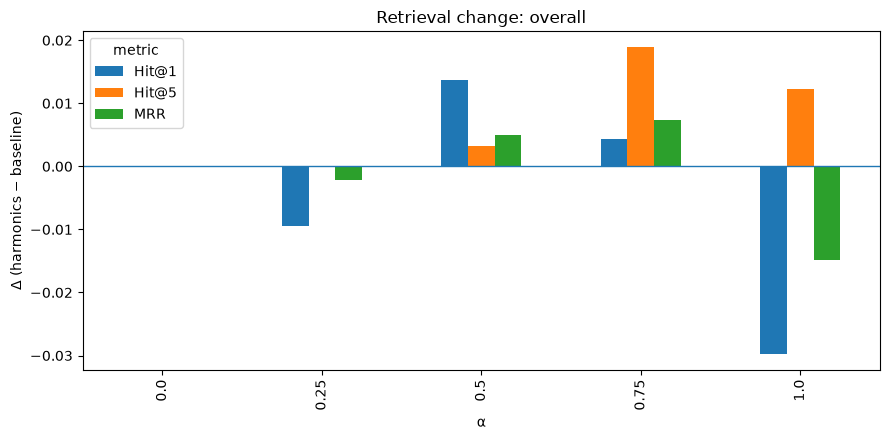

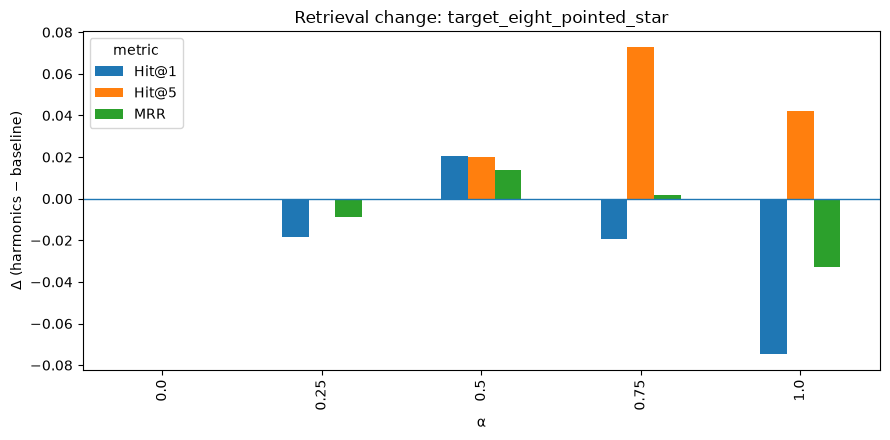

In [44]:
metric_names = {"hit_at_1": "Hit@1", "hit_at_5": "Hit@5", "mrr": "MRR"}
for scope in ("overall", "target_eight_pointed_star"):
    sub = comparison[comparison.scope == scope].pivot(
        index="alpha", columns="metric", values="delta"
    )[["hit_at_1", "hit_at_5", "mrr"]]
    ax = sub.rename(columns=metric_names).plot(kind="bar", figsize=(9, 4.5))
    ax.axhline(0, linewidth=1)
    ax.set(title=f"Retrieval change: {scope}", ylabel="Δ (harmonics − baseline)", xlabel="α")
    plt.tight_layout()
    plt.show()

## 3. Multi-class discrimination comparison

These are **pooled** precision, recall and F1 scores for Top-1 classification. Compare DINOv2 with Hybrid α=0.25, as stored in both JSON files.

In [45]:
def flatten_discrimination(data, experiment):
    rows = []
    for representation, report in data["multi_class_discrimination"].items():
        for label, scores in report["per_class"].items():
            rows.append({"experiment": experiment,
                         "representation": representation, "class_or_average": label,
                         "kind": "class", **scores})
        for avg in ("micro_avg", "macro_avg", "weighted_avg"):
            rows.append({"experiment": experiment,
                         "representation": representation, "class_or_average": avg,
                         "kind": "average", **report[avg]})
    return pd.DataFrame(rows)

discrimination = pd.concat(
    [flatten_discrimination(data, name) for name, data in experiments.items()],
    ignore_index=True,
)

keys = ["representation", "class_or_average", "kind"]
metric_columns = ["precision", "recall", "f1-score", "support"]
left = discrimination.loc[discrimination.experiment == "baseline", keys + metric_columns]
right = discrimination.loc[discrimination.experiment == "harmonics", keys + metric_columns]
discrim_comparison = left.merge(right, on=keys, suffixes=("_baseline", "_harmonics"), validate="one_to_one")
for metric in ("precision", "recall", "f1-score"):
    discrim_comparison[f"delta_{metric}"] = (
        discrim_comparison[f"{metric}_harmonics"] - discrim_comparison[f"{metric}_baseline"]
    )
assert (discrim_comparison.support_baseline == discrim_comparison.support_harmonics).all(),     "Different supports: check that datasets and query exclusions match."

def show_class_comparison(representation):
    cols = ["class_or_average", "support_baseline",
            "precision_baseline", "precision_harmonics", "delta_precision",
            "recall_baseline", "recall_harmonics", "delta_recall",
            "f1-score_baseline", "f1-score_harmonics", "delta_f1-score"]
    display(discrim_comparison.loc[
        (discrim_comparison.representation == representation) &
        (discrim_comparison.kind == "class"), cols
    ].round(4))

print("HYBRID α=0.25 — PER-CLASS TOP-1")
show_class_comparison("hybrid_025")
print("\nDINOv2 α=0.0 — PER-CLASS TOP-1")
show_class_comparison("dinov2")

HYBRID α=0.25 — PER-CLASS TOP-1


,class_or_average,support_baseline,precision_baseline,precision_harmonics,delta_precision,recall_baseline,recall_harmonics,delta_recall,f1-score_baseline,f1-score_harmonics,delta_f1-score
9,eight_petal_rosette,34.0,0.6667,0.6667,0.0000,0.6471,0.6471,0.0000,0.6567,0.6567,0.0000
10,eight_pointed_star,52.0,0.5821,0.5758,-0.0063,0.7500,0.7308,-0.0192,0.6555,0.6441,-0.0114
11,five_pointed_star,42.0,0.5854,0.5581,-0.0272,0.5714,0.5714,0.0000,0.5783,0.5647,-0.0136
12,rosette_other,31.0,0.6207,0.5938,-0.0269,0.5806,0.6129,0.0323,0.6000,0.6032,0.0032
13,six_pointed_star,41.0,0.5714,0.6207,0.0493,0.4878,0.4390,-0.0488,0.5263,0.5143,-0.0120
14,sunburst,37.0,0.8400,0.8750,0.0350,0.5676,0.5676,0.0000,0.6774,0.6885,0.0111



DINOv2 α=0.0 — PER-CLASS TOP-1


,class_or_average,support_baseline,precision_baseline,precision_harmonics,delta_precision,recall_baseline,recall_harmonics,delta_recall,f1-score_baseline,f1-score_harmonics,delta_f1-score
0,eight_petal_rosette,34.0,0.5556,0.5556,0.0,0.5882,0.5882,0.0,0.5714,0.5714,0.0
1,eight_pointed_star,52.0,0.6724,0.6724,0.0,0.7500,0.7500,0.0,0.7091,0.7091,0.0
2,five_pointed_star,42.0,0.5957,0.5957,0.0,0.6667,0.6667,0.0,0.6292,0.6292,0.0
3,rosette_other,31.0,0.5000,0.5000,0.0,0.5484,0.5484,0.0,0.5231,0.5231,0.0
4,six_pointed_star,41.0,0.6129,0.6129,0.0,0.4634,0.4634,0.0,0.5278,0.5278,0.0
5,sunburst,37.0,0.8750,0.8750,0.0,0.5676,0.5676,0.0,0.6885,0.6885,0.0


### 3.1 Compare micro/macro/weighted averages

In [46]:
avg_cols = ["representation", "class_or_average", "support_baseline",
            "precision_baseline", "precision_harmonics", "delta_precision",
            "recall_baseline", "recall_harmonics", "delta_recall",
            "f1-score_baseline", "f1-score_harmonics", "delta_f1-score"]
display(discrim_comparison.loc[
    discrim_comparison.kind == "average", avg_cols
].round(4))

,representation,class_or_average,support_baseline,precision_baseline,precision_harmonics,delta_precision,recall_baseline,recall_harmonics,delta_recall,f1-score_baseline,f1-score_harmonics,delta_f1-score
6,dinov2,micro_avg,237.0,0.6261,0.6261,0.0000,0.6076,0.6076,0.0000,0.6167,0.6167,0.0000
7,dinov2,macro_avg,237.0,0.6353,0.6353,0.0000,0.5974,0.5974,0.0000,0.6082,0.6082,0.0000
8,dinov2,weighted_avg,237.0,0.6408,0.6408,0.0000,0.6076,0.6076,0.0000,0.6163,0.6163,0.0000
15,hybrid_025,micro_avg,237.0,0.6261,0.6256,-0.0005,0.6076,0.5992,-0.0084,0.6167,0.6121,-0.0046
16,hybrid_025,macro_avg,237.0,0.6444,0.6483,0.0040,0.6008,0.5948,-0.0060,0.6157,0.6119,-0.0038
17,hybrid_025,weighted_avg,237.0,0.6383,0.6425,0.0042,0.6076,0.5992,-0.0084,0.6158,0.6110,-0.0048


### 3.2 Per-class precision, recall, and F1 deltas

This helps answer whether harmonics improve discrimination of five-, six-, and eight-pointed stars (the **point-counting problem**).

- **Precision:** Do harmonics reduce false positives for individual star classes?
- **Recall:** Do harmonics improve identification of actual five-, six-, and eight-pointed stars?
- **F1-score:** Do harmonics improve the balance between precision and recall?

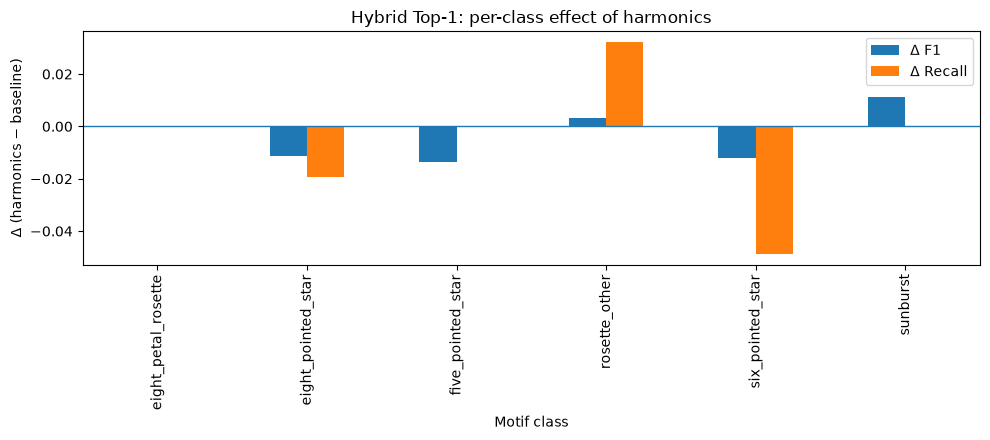

Star classes only:


,precision_baseline,precision_harmonics,delta_precision,recall_baseline,recall_harmonics,delta_recall,f1-score_baseline,f1-score_harmonics,delta_f1-score
class_or_average,,,,,,,,,
five_pointed_star,0.5854,0.5581,-0.0272,0.5714,0.5714,0.0000,0.5783,0.5647,-0.0136
six_pointed_star,0.5714,0.6207,0.0493,0.4878,0.4390,-0.0488,0.5263,0.5143,-0.0120
eight_pointed_star,0.5821,0.5758,-0.0063,0.7500,0.7308,-0.0192,0.6555,0.6441,-0.0114


In [47]:
star_labels = ["five_pointed_star", "six_pointed_star", "eight_pointed_star"]
sub = discrim_comparison.query("representation == 'hybrid_025' and kind == 'class'").copy()
sub = sub.set_index("class_or_average")
ax = sub[["delta_f1-score", "delta_recall"]].rename(
    columns={"delta_f1-score": "Δ F1", "delta_recall": "Δ Recall"}
).plot(kind="bar", figsize=(10, 4.5))
ax.axhline(0, linewidth=1)
ax.set(title="Hybrid Top-1: per-class effect of harmonics", ylabel="Δ (harmonics − baseline)", xlabel="Motif class")
plt.tight_layout()
plt.show()

print("Star classes only:")

metrics = [
    "precision_baseline", "precision_harmonics", "delta_precision",
    "recall_baseline", "recall_harmonics", "delta_recall",
    "f1-score_baseline", "f1-score_harmonics", "delta_f1-score",
]

display(sub.loc[star_labels, metrics].round(4))

## 4. Confusion Pattern Analysis

Investigate whether geometric feature improvements reduce
systematic misclassification between visually similar motifs.

Focus:
- Five-, six-, and eight-pointed star confusion.
- Changes in misclassification patterns relative to baseline.
- Whether improvements in recall introduce new false positives.

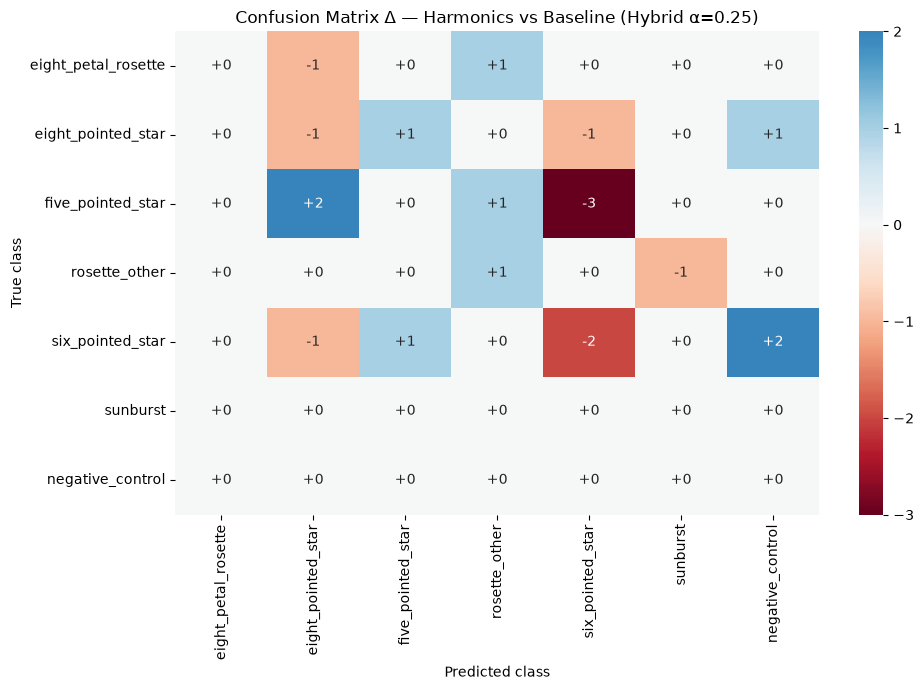

In [55]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

representation = "hybrid_025"

baseline_cm = baseline["multi_class_discrimination"][representation]
harmonics_cm = harmonics["multi_class_discrimination"][representation]

labels = baseline_cm["confusion_matrix_labels"]

assert labels == harmonics_cm["confusion_matrix_labels"]

cm_baseline = np.array(baseline_cm["confusion_matrix"])
cm_harmonics = np.array(harmonics_cm["confusion_matrix"])

delta_cm = cm_harmonics - cm_baseline

plt.figure(figsize=(10, 7))
sns.heatmap(
    delta_cm,
    annot=True,
    fmt="+d",
    cmap="RdBu",
    center=0,
    xticklabels=labels,
    yticklabels=labels,
)

plt.title("Confusion Matrix Δ — Harmonics vs Baseline (Hybrid α=0.25)")
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.tight_layout()


from pathlib import Path

output = Path("../results/v0.2_dev/exp01_harmonics/figures")
output.mkdir(parents=True, exist_ok=True)

plt.tight_layout()
plt.savefig(
    output / "confusion_delta_hybrid.png",
    dpi=300,
    bbox_inches="tight"
)
plt.savefig(output / "confusion_delta_hybrid.svg", bbox_inches="tight")
plt.show()

## 5. Notes for interpreting exp01

- A modest mean improvement should be checked against **fold variability**; five folds do not establish statistical significance by themselves.
- Improvements in **pooled macro F1** may differ from mean fold-level macro F1 (they have different averaging procedures).
- DINOv2 α=0 is a useful control: harmonics should not change the embedding-only evaluation when all other conditions are fixed.
- A higher **Hit@5** does not necessarily imply better Top-1 classification; likewise, voting accuracy requires a separate `class_voting.json` comparison.
- If a representation appears better on dev data, reserve the untouched held-out test set for the final selected model/experiment, not for iterative feature selection.